# 横磁場イジングモデル

## 横磁場イジングモデルとは

ある一つの方向のイジング相互作用に対して、それと垂直な向きの磁場を組み合わせたもの。

今回は以下のモデルを考える。

\begin{equation}
H = -J\sum_i{Z_i Z_{i+1}} -h\sum_i{X_i}
\end{equation}

- **第1項について**

    この項は隣り合うスピンを揃えようとする相互作用を表しています。

    実際に計算すると
    
    \begin{equation}
    \begin{aligned}
    Z_1 Z_0\ket{00} &= +1\ket{00} \\
    Z_1 Z_0\ket{11} &= +1\ket{11} \\
    Z_1 Z_0\ket{01} &= -1\ket{00} \\
    Z_1 Z_0\ket{10} &= -1\ket{11} \\
    \end{aligned}
    \end{equation}

    これから隣同士のスピンが揃っているとエネルギーが小さくなり、揃っていないとエネルギーが大きくなる。すなわちスピンが揃っている方が好まれるモデルになっている。

- **第2項について**

    スピンをZの軸からXの軸へ傾けるような量子揺らぎを表しています。


## 今回のゴール

$H$の基底エネルギー$E_0$と初期状態$\ket{+\cdots+}$からクエンチ後の横磁化$m_x(t)$の時間発展を求める。

## 今回行う解き方
1.  **厳密対角化**

    $2^n\times2^n$行列を対角化する。

1.  **Jordan-Wigner変換を用いてフェルミオンの問題に置き換える方法**

    フェルミオンの問題に置き換えて考えることで厳密に解くことができる。
    大まかな流れは

1.  **量子回路で解く方法（Trotter分解とVQE）**

    時間発展はTrotter分解で$e^{-iHt}$をゲートの積に近似して求め、基底エネルギーはVQE（変分量子固有値ソルバー）で求める。Trotter分解では精度を上げるほど多くのゲートが必要になる。

## 1.厳密対角化の一般論

### 1-1 基底エネルギー$E_0$

$H$を対角化し、その固有値の最小値が基底エネルギー$E_0$である。

### 1-2 横磁化$m_x(t)$

$m_x(t)$は以下のように計算できる。

\begin{equation}
m_x(t) = \bra{\psi(t)}M_x\ket{\psi(t)}, M_x = \frac{1}{n}\sum_{j=1}^{n}{X_j}
\end{equation}

$X_j$はそれぞれのサイトのx成分を測る演算子であり、jサイト目が
- $\ket{+}$のとき$+1$
- $\ket{-}$のとき$-1$

になるもの。$M_x$はそれの平均であると考えるとわかりやすい。

以下で$\psi(t)$を求める。シュレンディンガー方程式より

\begin{equation}
i\frac{d}{dt}\ket{\psi(t)} = H\ket{\psi(t)} \Rightarrow \ket{\psi(t)} = e^{-iHt}\ket{\psi_9}
\end{equation}

ここで初期状態$\psi_0$を固有基底で展開する。

\begin{equation}
\ket{\psi_0} = \sum_n c_n\ket{n}, c_n = \bra{n}\ket{\psi_0}
\end{equation}

これを先ほどの式に代入すると

\begin{equation}
\begin{aligned}
\ket{\psi(t)} 
&= e^{-iHt}\ket{\psi_9} \\
&= \sum_n e^{-iHt}c_n\ket{n} \\
&= \sum_n e^{-iE_{n}t}c_n\ket{n} (\because H\ket{n}=E_n\ket{n})\\
\end{aligned}
\end{equation}

このように固有状態の時間発展が追いやすいことを用いる。

これらより横磁化$m_x(t)$は

\begin{equation}
\begin{aligned}
m_x(t)
&= \bra{\psi(t)}M_x\ket{\psi(t)} \\
&= \sum_{m, n} c_m^{*}c_n e^{i(E_m - E_n)t}\bra{m}M_x\ket{n}
\end{aligned}
\end{equation}

である。

### 1-3 具体例を考えてみる

$n=2$のときの基底エネルギー$E_0$、初期状態$\ket{+\cdots+}$での横磁化$m_x(t)$を計算してみる。

- **基底エネルギー$E_0$**

  $n=2$のときのハミルトニアンを行列表示すると

  $$
  \begin{aligned}
  H 
  &= -JZ_1 Z_2 - h(X_1+X_2) \\
  &= -J\begin{pmatrix}1&0\\0&-1\end{pmatrix}\otimes\begin{pmatrix}1&0\\0&-1\end{pmatrix} - h\left(\begin{pmatrix}0&1\\1&0\end{pmatrix}\otimes\begin{pmatrix}1&0\\0&1\end{pmatrix} + \begin{pmatrix}1&0\\0&1\end{pmatrix}\otimes\begin{pmatrix}0&1\\1&0\end{pmatrix}\right) \\
  &= -J\begin{pmatrix}1&0&0&0\\0&-1&0&0\\0&0&-1&0\\0&0&0&1\end{pmatrix}
  - h\left(\begin{pmatrix}0&0&1&0\\0&0&0&1\\1&0&0&0\\0&1&0&0\end{pmatrix}
  + \begin{pmatrix}0&1&0&0\\1&0&0&0\\0&0&0&1\\0&0&1&0\end{pmatrix}\right) \\
  &= \begin{pmatrix}
  -J & -h & -h & 0\\
  -h & J & 0 & -h\\
  -h & 0 & J & -h\\
  0 & -h & -h & -J
  \end{pmatrix}
  \end{aligned}
  $$

  この行列の固有値を求めると

  $$
  \lambda = -\sqrt{J^2+4h^2}, -J, J, \sqrt{J^2+4h^2}
  $$

  よって基底エネルギーは

  $$
  E_0 = -\sqrt{J^2+4h^2}
  $$

- **横磁化$m_x(t)$**

  ここで、それぞれの固有状態は上の順に

  $$
  \begin{aligned}
  \ket{E_0} &= \cos{\frac{\theta}{2}}\ket{\phi_+}+\sin{\frac{\theta}{2}}\ket{\psi_+} \\
  \ket{E_1} &= \ket{\phi_-} \\
  \ket{E_2} &= \ket{\psi_-} \\
  \ket{E_3} &= -\sin{\frac{\theta}{2}}\ket{\phi_+}+\cos{\frac{\theta}{2}}\ket{\psi_+}
  \end{aligned}
  $$

  ここで

  $$
  \ket{\phi_\pm} = \frac{\ket{00}\pm\ket{11}}{\sqrt{2}}, \ket{\psi_\pm} = \frac{\ket{01}\pm\ket{10}}{\sqrt{2}}
  $$

  とおいた。
  初期状態$\ket{++}$を基底展開すると

  $$
  \begin{aligned}
  \ket{++}
  &= \frac{1}{2}(\ket{00}+\ket{01}+\ket{10}+\ket{11}) \\
  &= \frac{\cos{\frac{\theta}{2}+\sin{\frac{\theta}{2}}}}{\sqrt{2}}\ket{E_0}+\frac{\cos{\frac{\theta}{2}-\sin{\frac{\theta}{2}}}}{\sqrt{2}}\ket{E_3}
  \end{aligned}
  $$

  よって

  $$
  c_0 = \frac{\cos\frac{\theta}{2}+\sin\frac{\theta}{2}}{\sqrt{2}},\quad
  c_3 = \frac{\cos\frac{\theta}{2}-\sin\frac{\theta}{2}}{\sqrt{2}},\quad
  c_1 = c_2 = 0
  $$

  であり、

  $$
  |c_0|^2 = \frac{1+\sin\theta}{2},\quad
  |c_3|^2 = \frac{1-\sin\theta}{2},\quad
  c_0 c_3 = \frac{\cos\theta}{2}
  $$

  また、$M_x = \frac{1}{2}(X_1+X_2)$について、$(X_1+X_2)\ket{\phi_+} = 2\ket{\psi_+}$, $(X_1+X_2)\ket{\psi_+} = 2\ket{\phi_+}$ より、
  $\{\ket{\phi_+},\ket{\psi_+}\}$ 部分空間で $M_x$ は $\sigma_x$ として働く。したがって

  $$
  \bra{E_0}M_x\ket{E_0} = \sin\theta,\quad
  \bra{E_3}M_x\ket{E_3} = -\sin\theta,\quad
  \bra{E_0}M_x\ket{E_3} = \bra{E_3}M_x\ket{E_0} = \cos\theta
  $$

  これらから

  $$
  \begin{aligned}
  m_x(t) 
  &= \sum_{m, n=0}^{3} c_m^{*}c_n e^{i(E_m - E_n)t}\bra{m}M_x\ket{n} \\
  &= |c_0|^2\bra{E_0}M_x\ket{E_0} + |c_3|^2\bra{E_3}M_x\ket{E_3}
      + c_0 c_3\left(e^{i(E_0-E_3)t} + e^{-i(E_0-E_3)t}\right)\bra{E_0}M_x\ket{E_3} \\
  &= \left(|c_0|^2 - |c_3|^2\right)\sin\theta + 2c_0c_3\cos\theta\cos\left[(E_3-E_0)t\right] \\
  &= \sin^2\theta + \cos^2\theta\,\cos\left(2\sqrt{J^2+4h^2}\,t\right) \\
  &= \frac{4h^2 + J^2\cos\left(2\sqrt{J^2+4h^2}\,t\right)}{J^2+4h^2}
  \end{aligned}
  $$

### 1-4 コードで確かめる

$n=2$の場合について、実際にpythonで計算してみる。

基底エネルギー E0 = -1.414214


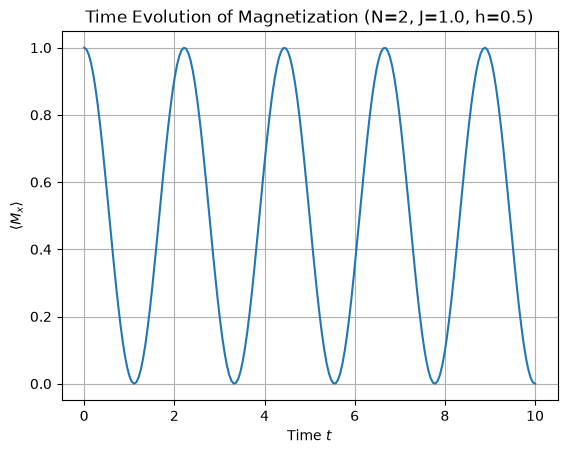

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1-1, 1-2 の計算に使う関数は共通パッケージ qmb から読み込む
#   site_op, plus_state                   : src/qmb/operators.py
#   hamiltonian, magnetization_x          : src/qmb/models.py
#   ground_state, time_evolve_expectation : src/qmb/ed.py
# 実装を見たいときは、Jupyterで関数名の後に ?? を付けて実行する（例: hamiltonian??）
from qmb.operators import site_op, plus_state
from qmb.models import tfim_hamiltonian as hamiltonian, magnetization_x
from qmb.ed import ground_state, time_evolve_expectation

# 例: N=2, J=1, h=0.5 の場合の基底状態と時間発展
N = 2
J = 1.0
h = 0.5
H = hamiltonian(N, J, h, pbc=False)   # N=2 は開放境界（周期境界だとボンドを2回数える）

# 基底エネルギーE_0
E0, psi_g = ground_state(H)

print(f"基底エネルギー E0 = {E0:.6f}")

# m_x(t)
psi0 = plus_state(N)
A = magnetization_x(N)
ts = np.linspace(0, 10, 200)
expectations = time_evolve_expectation(H, psi0, A, ts)

# グラフ
plt.plot(ts, expectations)
plt.xlabel("Time $t$")
plt.ylabel(r"$\langle M_x \rangle$")
plt.title(f"Time Evolution of Magnetization (N={N}, J={J}, h={h})")
plt.grid()
plt.show()

1-3の結果と比較する。それぞれに$J=1, h=0.5$を代入すると

- **基底エネルギー$E_0$**
  $$
  \begin{aligned}
    E_0 
    &= -\sqrt{J^2+4h^2} \\
    &= -\sqrt{2} \\
    &= -1.4142\cdots
  \end{aligned}
  $$
1-4の結果と一致している
- **横磁化m_x(t)**
  $$
  \begin{aligned}
  m_x(t) 
  &= \frac{4h^2 + J^2\cos\left(2\sqrt{J^2+4h^2}\,t\right)}{J^2+4h^2} \\
  &= \frac{1}{2}(1+\cos{2\sqrt{2}t}) \\
  &= \cos^2(\sqrt{2}t)
  \end{aligned}
  $$
1-4のグラフと比較すると、以下のように一致している。

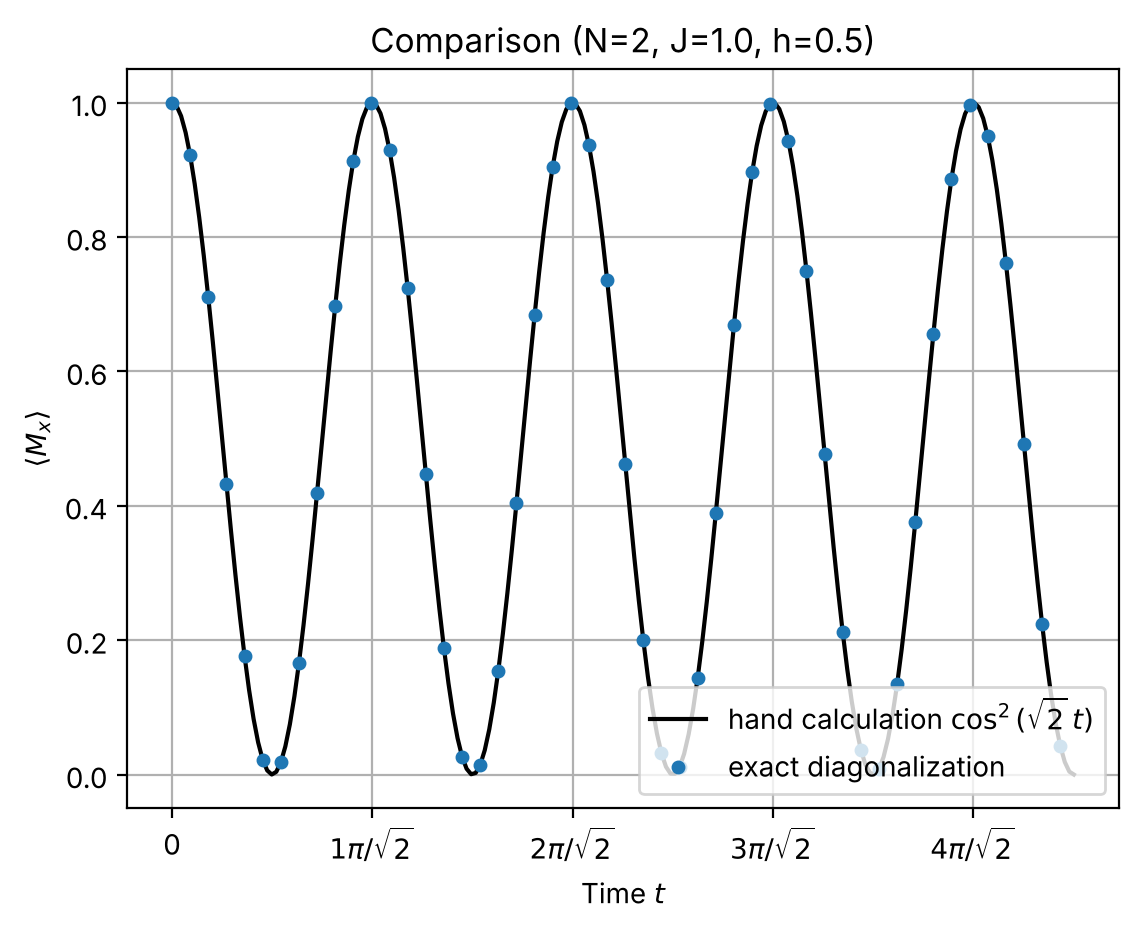

In [2]:
# m_x(t) = cos²(√2 t)
m_hand = np.cos(np.sqrt(2) * ts)**2

# グラフで重ねる
T = np.pi / np.sqrt(2)   # 周期
plt.plot(ts, m_hand, "k-", label=r"hand calculation $\cos^2(\sqrt{2}\,t)$")
plt.plot(ts[::4], expectations[::4], "o", ms=4, label="exact diagonalization")
plt.xticks([k * T for k in range(5)],["0"] + [rf"${k}\pi/\sqrt{{2}}$" for k in range(1, 5)])
plt.xlabel("Time $t$")
plt.ylabel(r"$\langle M_x \rangle$")
plt.title(f"Comparison (N={N}, J={J}, h={h})")
plt.legend(loc="lower right")
plt.grid()
plt.show()

n=2のようなnが小さい場合は今回のように行列を対角化することで計算できるが、nが大きくなるにつれこの方法は$n^2\times n^2$行列の対角化をしなくてはならず、計算コストが大きい。nが大きい場合でも効率よく計算できる方法が次のJordan-Wigner変換を用いた方法である。

---
**次へ**: [2. Jordan-Wigner変換を用いてフェルミオンの問題に置き換える方法](02_jordan_wigner.ipynb)